# Этап 0. Окружение и пустая highway-v0

Проверяем, что среда запускается, и записываем ее параметры по умолчанию. Здесь ничего не меняем, только смотрим, с чем будем работать.

In [1]:
import sys
import gymnasium as gym
import highway_env
import matplotlib.pyplot as plt
from pathlib import Path

print('Python', sys.version.split()[0])
print('highway-env', highway_env.__version__ if hasattr(highway_env, '__version__') else '?')
print('gymnasium', gym.__version__)
FIG = Path('..') / 'results' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

Python 3.11.17
highway-env 1.12.1
gymnasium 1.4.0


## Параметры highway-v0 по умолчанию

In [2]:
env = gym.make('highway-v0', render_mode='rgb_array')
cfg = env.unwrapped.config
keys = ['lanes_count', 'vehicles_count', 'vehicles_density', 'duration',
        'simulation_frequency', 'policy_frequency', 'other_vehicles_type',
        'collision_reward', 'high_speed_reward', 'right_lane_reward',
        'reward_speed_range', 'offroad_terminal']
for k in keys:
    print(f'{k:22s} {cfg[k]}')
print('observation', cfg['observation'])
print('action     ', cfg['action'])

lanes_count            4
vehicles_count         50
vehicles_density       1
duration               40
simulation_frequency   15
policy_frequency       1
other_vehicles_type    highway_env.vehicle.behavior.IDMVehicle
collision_reward       -1
high_speed_reward      0.4
right_lane_reward      0.1
reward_speed_range     [20, 30]
offroad_terminal       False
observation {'type': 'Kinematics'}
action      {'type': 'DiscreteMetaAction'}


Что важно для следующих этапов:
- **simulation_frequency = 15 Гц**: машины двигаются шагами по 1/15 с ≈ 0,067 с. Время реакции RSS ρ = 0,5 с — это 7–8 таких шагов.
- **policy_frequency = 1 Гц**: агент выбирает действие раз в секунду, а между решениями симулятор делает 15 шагов. Поэтому фильтр нельзя ставить только между решениями агента: он должен работать внутри этих 15 шагов.
- **duration = 40 с**: эпизод ограничен по времени (пункт 9 письма).
- Наблюдение `Kinematics` видит только 5 ближайших машин; фильтр будет видеть все машины в радиусе ~150 м напрямую из симулятора (пункт 2 письма).

## Константы машин

In [3]:
from highway_env.vehicle.kinematics import Vehicle
from highway_env.vehicle.behavior import IDMVehicle
print('Длина / ширина машины, м:', Vehicle.LENGTH, '/', Vehicle.WIDTH)
print('Скорость, м/с: от', Vehicle.MIN_SPEED, 'до', Vehicle.MAX_SPEED)
print('IDM: желаемое торможение COMFORT_ACC_MIN =', IDMVehicle.COMFORT_ACC_MIN)
print('IDM: обрезка ускорения ACC_MAX = ±', IDMVehicle.ACC_MAX)

Длина / ширина машины, м: 5.0 / 2.0
Скорость, м/с: от -40.0 до 40.0
IDM: желаемое торможение COMFORT_ACC_MIN = -5.0
IDM: обрезка ускорения ACC_MAX = ± 6.0


IDM-машина может тормозить до 6 м/с² (обрезка `ACC_MAX`), а RSS предполагает, что никто не тормозит сильнее a_max,brake = 5 м/с². На этапе 2 фоновым машинам ограничим торможение 5 м/с² (пункт 3 письма).

`MIN_SPEED = -40`: симулятор сам не останавливает машину на нуле, при сильном торможении она может поехать назад. Для нарушителя это нужно будет учесть.

## Пустой эпизод: агент держит полосу и скорость (действие IDLE)

шагов агента: 13 | время, с: 13.0
столкновение: True | по времени: False
машин на дороге: 51


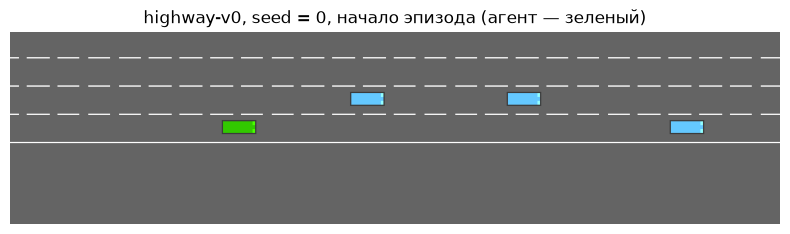

In [4]:
obs, info = env.reset(seed=0)
frame0 = env.render()
steps, terminated, truncated = 0, False, False
while not (terminated or truncated):
    obs, reward, terminated, truncated, info = env.step(1)  # 1 = IDLE
    steps += 1
print('шагов агента:', steps, '| время, с:', env.unwrapped.time)
print('столкновение:', env.unwrapped.vehicle.crashed, '| по времени:', truncated)
print('машин на дороге:', len(env.unwrapped.road.vehicles))

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.imshow(frame0); ax.axis('off')
ax.set_title('highway-v0, seed = 0, начало эпизода (агент — зеленый)')
fig.savefig(FIG / '00_highway_frame.png', dpi=150, bbox_inches='tight')
plt.show()
env.close()

## Как часто «тупой» агент сталкивается без всяких нарушителей

In [5]:
env = gym.make('highway-v0')
crash_times = []
for seed in range(30):
    env.reset(seed=seed)
    terminated = truncated = False
    while not (terminated or truncated):
        _, _, terminated, truncated, _ = env.step(1)
    if terminated:
        crash_times.append(env.unwrapped.time)
env.close()
print(f'столкновений: {len(crash_times)} из 30')
print('время столкновения, с:', crash_times)

столкновений: 28 из 30
время столкновения, с: [13.0, 39.0, 9.0, 25.0, 28.0, 18.0, 13.0, 28.0, 21.0, 23.0, 6.0, 37.0, 3.0, 20.0, 10.0, 22.0, 30.0, 19.0, 30.0, 28.0, 11.0, 13.0, 6.0, 18.0, 19.0, 17.0, 17.0, 8.0]


Агент с постоянным действием IDLE не подстраивается под машину впереди и почти всегда во что-то врезается, хотя нарушителей в сцене нет. Значит:
- в пилоте этапа 3 (агент без PPO) столкновения будут и при β = 1, причем по вине самого агента. Именно эти случаи RSS-фильтр обязан предотвращать;
- проверка номинального режима (этап 5) должна показать, что с фильтром таких столкновений нет. Если они останутся, фильтр реализован неверно.